# 混淆矩陣圖解：ML 慢慢學 EP06 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v07-confusion-matrix/notebook.ipynb)

這本 notebook 產生影片裡焚化爐範例的**每一張資料圖和每一個數字**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every chart and number of the incinerator example in EP06 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

接續 EP05：模型每一分鐘估計「接下來一小時的一氧化碳（CO）平均，會不會超過廠內自訂的警戒值 30 ppm」的機率，機率高過**門檻**就發警報。
EP05 最後的問題：**該響的警報沒響，和不該響卻響了，哪一種錯比較糟？** 這一集先學會**怎麼數這兩種錯**，再用它們來選門檻。

| 段落 | 對應影片 |
|---|---|
| 1. 重建 EP05 的資料和模型（一個數字都不改） | 第 2 段 |
| 2. 四種結果：混淆矩陣 | 第 3 段 |
| 3. 準確率的陷阱 | 第 4 段 |
| 4. 精確率與召回率 | 第 5 段 |
| 5. 門檻一動，兩個數字就拉扯 | 第 6 段 |
| 6. 先訂規則，再用驗證集選門檻 | 第 7 段 |
| 7. 鎖定之前：檢查各段資料「超過警戒值」的比例 | — |
| 8. 鎖定設定（之後不再改） | — |
| 9. 測試集：全新的 40 天，只評估這一次 | 第 8 段 |
| 10. 匯出資料給影片使用 | — |

**流程紀律**：模型照 EP05 鎖定的設定重建，不重新挑任何東西。門檻只用驗證集、照事先寫好的規則選。測試集在第 8 段鎖定之後才產生，只評估一次。EP05 用過的模擬種子（2026、2028、2029–2034）這一集都不拿來評分。

**單位**：模型每一分鐘判斷一次，所以下面所有的「次數」都是**分鐘數**。相鄰的分鐘答案幾乎一樣（都在看重疊的 60 分鐘），所以 5,700 分鐘不等於 5,700 個互相獨立的例子。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

PAPER, INK, RED, BLUE, AMBER, TEAL = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B", "#2A9D8F"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def cross_entropy(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())

## 1. 重建 EP05 的資料和模型（一個數字都不改）
模擬方式、亂數種子、訓練集（第 1–10 天）、驗證集（第 11–14 天）、梯度下降的設定，全部和 EP05 notebook 相同。
最後核對：重建出來的權重必須和 EP05 匯出的 `v06.json` 一致。

In [2]:
def lag(x, tau):
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

CO_BASE, CO_SMAX = 14.0, 1.5
A_O2, A_TEMP = 1.8, 0.2
TAU_U, SD_U = 40, 0.3

def simulate(seed, days):
    # 和 EP05 notebook 第 1 段完全相同
    rng = np.random.default_rng(seed)
    N = days * 1440
    MU, SD = 2050.0, 150.0
    PHI = np.exp(-1 / 120)
    lhv = np.empty(N); lhv[0] = MU
    noise = rng.normal(0, SD * np.sqrt(1 - PHI ** 2), N)
    for i in range(1, N):
        lhv[i] = MU + PHI * (lhv[i - 1] - MU) + noise[i]
    lhv = np.clip(lhv, 1500, 2500)
    F_set = np.empty(N); i, level = 0, 12.5
    while i < N:
        length = int(rng.integers(120, 360))
        level = float(np.clip(level + rng.normal(0, 0.7), 10.5, 14.5))
        F_set[i:i + length] = level; i += length
    feed = lag(F_set, 15) + rng.normal(0, 0.15, N)
    trim = np.empty(N); trim[0] = 0.0
    PT = np.exp(-1 / 180)
    e_trim = rng.normal(0, 0.06 * np.sqrt(1 - PT ** 2), N)
    for i in range(1, N):
        trim[i] = PT * trim[i - 1] + e_trim[i]
    air = lag(3000 * F_set * (1 + trim), 5) + rng.normal(0, 400, N)
    Q0 = 12.5 * MU
    q = feed * lhv / Q0
    air_rel = air / (3000 * 12.5)
    temp = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1) + rng.normal(0, 5, N)
    o2 = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1) + rng.normal(0, 0.2, N)
    steam = lag(feed * lhv * 0.8 / 670 - 4 * (air_rel - 1), 10) + rng.normal(0, 0.3, N)
    raw = np.c_[feed, air, temp, o2]
    # 範圍檢查：爐溫 > 850°C、排氣含氧量 ≥ 6% 是法規；含氧量 < 10%、空氣 > 10000 是模擬自己設的範圍
    assert temp.min() > 850 and 6 <= o2.min() and o2.max() < 10 and air.min() > 10000

    r2 = np.random.default_rng(seed + 500)
    o2_true = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1)
    temp_true = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1)
    PU = np.exp(-1 / TAU_U)
    u = np.empty(N); u[0] = 0.0
    e_u = r2.normal(0, SD_U * np.sqrt(1 - PU ** 2), N)
    for i in range(1, N):
        u[i] = PU * u[i - 1] + e_u[i]
    s = A_O2 * (8.0 - o2_true) + A_TEMP * (960 - temp_true) / 10 + u
    s = CO_SMAX * np.tanh(s / CO_SMAX)
    co = CO_BASE * np.exp(s) * np.exp(r2.normal(0, 0.15, N))
    co_hour = np.convolve(co, np.ones(60) / 60, mode="valid")
    assert co_hour.max() < 100, "模擬的 CO 一小時平均必須低於法規的 100 ppm"
    return raw, steam, co

NAMES = ["進料量", "一次空氣流量", "爐溫", "含氧量"]
H, THR = 60, 30.0

def make_xy(raw, co):
    cs = np.cumsum(np.r_[0.0, co])
    rows = np.arange(len(co) - H)
    co_next = (cs[rows + 1 + H] - cs[rows + 1]) / H
    return raw[rows], co_next, (co_next > THR).astype(int)

raw, steam, co = simulate(2026, 14)
X, co_next, y = make_xy(raw, co)
TR = np.arange(0, 10 * 1440 - H)
VA = np.arange(10 * 1440, 14 * 1440 - H)
mu, sd = X[TR].mean(0), X[TR].std(0)
A_tr = np.c_[np.ones(len(TR)), (X[TR] - mu) / sd]
A_va = np.c_[np.ones(len(VA)), (X[VA] - mu) / sd]

LR, ITERS = 1.0, 5000
w = np.zeros(A_tr.shape[1])
for it in range(ITERS):
    p = sigmoid(A_tr @ w)
    w -= LR * A_tr.T @ (p - y[TR]) / len(TR)
W_EP05 = w.copy()

ep05 = Path("../v06-logistic-regression/data/v06.json")
if ep05.exists():
    lock05 = json.loads(ep05.read_text(encoding="utf-8"))["lock"]
    assert np.allclose(W_EP05, lock05["w"], atol=1e-5) and np.allclose(mu, lock05["mu"], atol=1e-4), "和 EP05 的模型不一致"
    print("模型和 EP05 一致（權重、標準化參數都相同）")
print("權重：", np.round(W_EP05, 4))

def predict(Xrows):
    return sigmoid(np.c_[np.ones(len(Xrows)), (Xrows - mu) / sd] @ W_EP05)

p_va, y_va = predict(X[VA]), y[VA]
print(f"驗證集 {len(VA):,} 分鐘，真的超過警戒值的有 {y_va.sum():,} 分鐘（{100 * y_va.mean():.1f}%）")
print(f"驗證集交叉熵 {cross_entropy(y_va, p_va):.3f}（EP05 公布的是 0.293）")

模型和 EP05 一致（權重、標準化參數都相同）
權重： [-6.6207 -1.7533 -2.2322  1.468  -0.3662]
驗證集 5,700 分鐘，真的超過警戒值的有 1,156 分鐘（20.3%）
驗證集交叉熵 0.293（EP05 公布的是 0.293）


## 2. 四種結果：混淆矩陣
門檻先用 0.5：模型說的機率 ≥ 0.5 就響警報。每一分鐘拿「警報有沒有響」和「接下來一小時真的有沒有超過警戒值」比，只有四種結果：

| | 警報響 | 警報沒響 |
|---|---|---|
| **真的超過** | 命中（TP，真陽性） | **漏報**（FN，偽陰性） |
| **沒有超過** | **誤報**（FP，偽陽性） | 正確不報（TN，真陰性） |

這張 2×2 的表叫**混淆矩陣**（confusion matrix）。對角線是做對的，另外兩格就是 EP05 說的兩種錯。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


驗證集，門檻 0.5（單位：分鐘）
  命中    823   漏報    333
  誤報    147   正確不報  4,397
  準確率 0.916  精確率 0.848  召回率 0.712  響警報的時間 17.0%


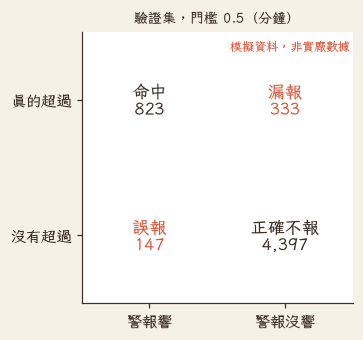

In [3]:
def confusion(yv, alarm):
    yv, alarm = np.asarray(yv).astype(bool), np.asarray(alarm).astype(bool)
    return {"tp": int((yv & alarm).sum()), "fn": int((yv & ~alarm).sum()),
            "fp": int((~yv & alarm).sum()), "tn": int((~yv & ~alarm).sum())}

def scores(c):
    n = c["tp"] + c["fn"] + c["fp"] + c["tn"]
    acc = (c["tp"] + c["tn"]) / n
    prec = c["tp"] / (c["tp"] + c["fp"]) if (c["tp"] + c["fp"]) > 0 else None   # 從沒響過：精確率沒有定義
    rec = c["tp"] / (c["tp"] + c["fn"]) if (c["tp"] + c["fn"]) > 0 else None    # 從沒超過：召回率沒有定義
    return {"n": n, "accuracy": acc, "precision": prec, "recall": rec, "alarm_share": (c["tp"] + c["fp"]) / n}

def show(name, c):
    s = scores(c)
    f = lambda v: "—（沒有定義）" if v is None else f"{v:.3f}"
    print(f"{name}\n  命中 {c['tp']:>6,}   漏報 {c['fn']:>6,}\n  誤報 {c['fp']:>6,}   正確不報 {c['tn']:>6,}"
          f"\n  準確率 {f(s['accuracy'])}  精確率 {f(s['precision'])}  召回率 {f(s['recall'])}  響警報的時間 {100 * s['alarm_share']:.1f}%")
    return s

cm_va_05 = confusion(y_va, p_va >= 0.5)
sc_va_05 = show("驗證集，門檻 0.5（單位：分鐘）", cm_va_05)
assert sum(cm_va_05.values()) == len(VA)

fig, ax = plt.subplots(figsize=(3.6, 3.2))
grid = np.array([[cm_va_05["tp"], cm_va_05["fn"]], [cm_va_05["fp"], cm_va_05["tn"]]])
ax.imshow(np.zeros((2, 2)), cmap="Greys", vmin=0, vmax=1)
names = [["命中", "漏報"], ["誤報", "正確不報"]]
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{names[r][c]}\n{grid[r, c]:,}", ha="center", va="center", fontsize=11, color=RED if r != c else INK)
ax.set_xticks([0, 1], ["警報響", "警報沒響"]); ax.set_yticks([0, 1], ["真的超過", "沒有超過"])
ax.set_title("驗證集，門檻 0.5（分鐘）", fontsize=9); tag(ax); plt.show()

## 3. 準確率的陷阱
**準確率（accuracy）** = 做對的分鐘數 ÷ 全部分鐘數 =（命中 + 正確不報）÷ 全部。
拿一個「什麼都不做」的對照組來比：**永遠不響警報**。它從來不誤報，但真的超過的時候一次也抓不到。

In [4]:
cm_va_never = confusion(y_va, np.zeros(len(VA), bool))
sc_va_never = show("驗證集，永遠不響", cm_va_never)
print(f"\n永遠不響的準確率 = 沒超過的比例 = {1 - y_va.mean():.3f}：一次都沒抓到，準確率還是有 {100 * (1 - y_va.mean()):.0f}%。")
print(f"模型（門檻 0.5）的準確率 {sc_va_05['accuracy']:.3f}，只比它高 {100 * (sc_va_05['accuracy'] - sc_va_never['accuracy']):.1f} 個百分點，"
      f"但漏報從 {cm_va_never['fn']:,} 分鐘降到 {cm_va_05['fn']:,} 分鐘。")
print("超過警戒值越少見，『永遠不響』的準確率就越高：準確率一個數字，看不出漏報有多少。")

驗證集，永遠不響
  命中      0   漏報  1,156
  誤報      0   正確不報  4,544
  準確率 0.797  精確率 —（沒有定義）  召回率 0.000  響警報的時間 0.0%

永遠不響的準確率 = 沒超過的比例 = 0.797：一次都沒抓到，準確率還是有 80%。
模型（門檻 0.5）的準確率 0.916，只比它高 11.9 個百分點，但漏報從 1,156 分鐘降到 333 分鐘。
超過警戒值越少見，『永遠不響』的準確率就越高：準確率一個數字，看不出漏報有多少。


## 4. 精確率與召回率
把兩種錯分開看：

- **精確率（precision）** = 命中 ÷（命中 + 誤報）：**警報響的時候，有幾成是真的**。誤報越多，精確率越低。
- **召回率（recall）** = 命中 ÷（命中 + 漏報）：**真的超過的時候，有幾成警報有響**。漏報越多，召回率越低。

「永遠不響」的召回率是 0；「永遠響」的召回率是 1，但精確率只等於超過警戒值的比例。

In [5]:
cm_va_always = confusion(y_va, np.ones(len(VA), bool))
sc_va_always = show("驗證集，永遠響", cm_va_always)
print(f"\n模型（門檻 0.5）：警報響的時間裡，{100 * sc_va_05['precision']:.0f}% 真的超過（精確率）；"
      f"真的超過的時間裡，{100 * sc_va_05['recall']:.0f}% 有響（召回率）。")

驗證集，永遠響
  命中  1,156   漏報      0
  誤報  4,544   正確不報      0
  準確率 0.203  精確率 0.203  召回率 1.000  響警報的時間 100.0%

模型（門檻 0.5）：警報響的時間裡，85% 真的超過（精確率）；真的超過的時間裡，71% 有響（召回率）。


## 5. 門檻一動，兩個數字就拉扯
門檻從 0.05 到 0.95（每 0.05 一格），在驗證集上各算一次。門檻調低：響警報的時間變多，漏報變少（召回率上升），誤報變多（精確率通常下降）。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


 門檻   命中   漏報   誤報   精確率  召回率  準確率  響警報的時間
 0.05   1023    133   1049   0.494   0.885   0.793    36.4%
 0.10   1017    139    754   0.574   0.880   0.843    31.1%
 0.15   1010    146    624   0.618   0.874   0.865    28.7%
 0.20    995    161    505   0.663   0.861   0.883    26.3%
 0.25    969    187    409   0.703   0.838   0.895    24.2%
 0.30    932    224    347   0.729   0.806   0.900    22.4%
 0.35    914    242    294   0.757   0.791   0.906    21.2%
 0.40    894    262    244   0.786   0.773   0.911    20.0%
 0.45    863    293    199   0.813   0.747   0.914    18.6%
 0.50    823    333    147   0.848   0.712   0.916    17.0%
 0.55    772    384    116   0.869   0.668   0.912    15.6%
 0.60    713    443     86   0.892   0.617   0.907    14.0%
 0.65    638    518     58   0.917   0.552   0.899    12.2%
 0.70    561    595     39   0.935   0.485   0.889    10.5%
 0.75    488    668     23   0.955   0.422   0.879     9.0%
 0.80    369    787     11   0.971   0.319   0.860     6.

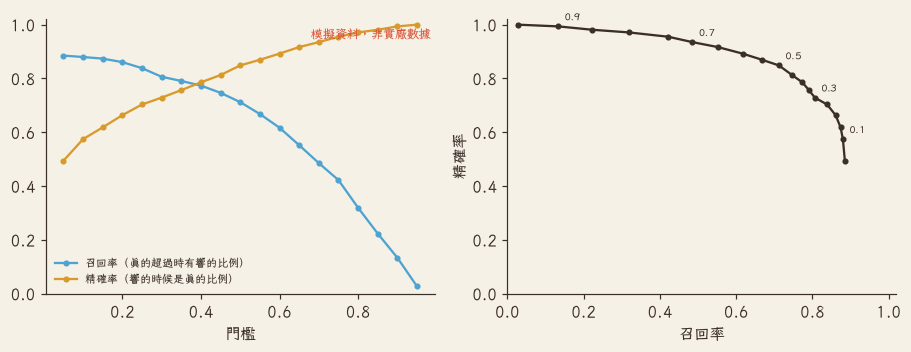

In [6]:
THR_GRID = np.round(np.arange(0.05, 0.951, 0.05), 2)
sweep = []
for t in THR_GRID:
    c = confusion(y_va, p_va >= t); s = scores(c)
    sweep.append({"thr": float(t), **c, "precision": s["precision"], "recall": s["recall"], "accuracy": s["accuracy"], "alarm_share": s["alarm_share"]})
print(" 門檻   命中   漏報   誤報   精確率  召回率  準確率  響警報的時間")
for r in sweep:
    print(f" {r['thr']:.2f}  {r['tp']:>5}  {r['fn']:>5}  {r['fp']:>5}   {r['precision']:.3f}   {r['recall']:.3f}   {r['accuracy']:.3f}   {100 * r['alarm_share']:5.1f}%")

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.3))
axs[0].plot(THR_GRID, [r["recall"] for r in sweep], "o-", color=BLUE, ms=3, label="召回率（真的超過時有響的比例）")
axs[0].plot(THR_GRID, [r["precision"] for r in sweep], "o-", color=AMBER, ms=3, label="精確率（響的時候是真的比例）")
axs[0].set_xlabel("門檻"); axs[0].set_ylim(0, 1.02); axs[0].legend(frameon=False, fontsize=7); tag(axs[0])
axs[1].plot([r["recall"] for r in sweep], [r["precision"] for r in sweep], "o-", color=INK, ms=3)
for r in sweep:
    if r["thr"] in (0.1, 0.3, 0.5, 0.7, 0.9):
        axs[1].annotate(f"{r['thr']:.1f}", (r["recall"], r["precision"]), textcoords="offset points", xytext=(4, 4), fontsize=7)
axs[1].set_xlabel("召回率"); axs[1].set_ylabel("精確率"); axs[1].set_xlim(0, 1.02); axs[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## 6. 先訂規則，再用驗證集選門檻
哪一種錯比較糟，沒有標準答案，要看**代價**。這裡用一個**示意**的情境（不是任何工廠的規定）：

- 漏報：CO 偏高的時候沒人注意，燃燒不完全的狀況拖得更久。
- 誤報：操作員要多看一次畫面、多確認一次；太多的話，大家會開始不理警報（狼來了）。

### 6.1 第一次寫的規則：召回率至少 0.90（做不到）
第一次寫的規則是：「真的超過的時間，至少九成要有警報（驗證集召回率 ≥ 0.90），在這個條件下取誤報最少的門檻」。
上面的表顯示，在事先定好的門檻格點（0.05–0.95，每 0.05 一格）裡，最低的 0.05 召回率也只有大約 0.885，**沒有一個格點達到 0.90**。這不代表模型怎麼調都抓不到：門檻再往下（格點以外），召回率還會升高；門檻 0 就是每分鐘都響，召回率是 1，只是誤報也非常多。規則是照事先定好的格點寫的，所以這個規則在驗證集上無解，換成 6.2 的規則。這時候測試集還沒有產生，換規則只用到驗證集。

In [7]:
RECALL_TARGET = 0.90
best_recall = max(r["recall"] for r in sweep)
print(f"驗證集上最高的召回率：{best_recall:.3f}（門檻 {min(THR_GRID):.2f}）；召回率 ≥ {RECALL_TARGET} 的門檻：{[r['thr'] for r in sweep if r['recall'] >= RECALL_TARGET] or '沒有'}")

驗證集上最高的召回率：0.885（門檻 0.05）；召回率 ≥ 0.9 的門檻：沒有


### 6.2 用代價來選：總代價最小的門檻
把兩種錯換成代價，加起來越小越好：**總代價 = 漏報分鐘數 × 漏報的代價 + 誤報分鐘數 × 誤報的代價**。

> **規則：假設漏報一分鐘的代價是誤報一分鐘的 5 倍（示意），在驗證集上選總代價最小的門檻（0.05 一格）。**

對照：如果兩種錯**一樣貴**（1 : 1），總代價就是「錯的分鐘數」，最小的地方就是**準確率最高**的地方。準確率其實就是「把兩種錯當成一樣貴」。

漏報 : 誤報 = 5 : 1 → 總代價最小的門檻 0.20
漏報 : 誤報 = 1 : 1 → 總代價最小的門檻 0.50（也就是準確率最高的門檻，準確率 0.916）
代價比例和門檻： 1:1 → 0.50、3:1 → 0.25、5:1 → 0.20、10:1 → 0.15
（理論上，如果機率估得很準，最好的門檻是 誤報代價 ÷（誤報代價 + 漏報代價）：1:1 → 0.5，5:1 → 0.17）

驗證集，選出的門檻 0.20
  命中    995   漏報    161
  誤報    505   正確不報  4,039
  準確率 0.883  精確率 0.663  召回率 0.861  響警報的時間 26.3%

和門檻 0.5 比：漏報 333 → 161 分鐘；誤報 147 → 505 分鐘；準確率 0.916 → 0.883


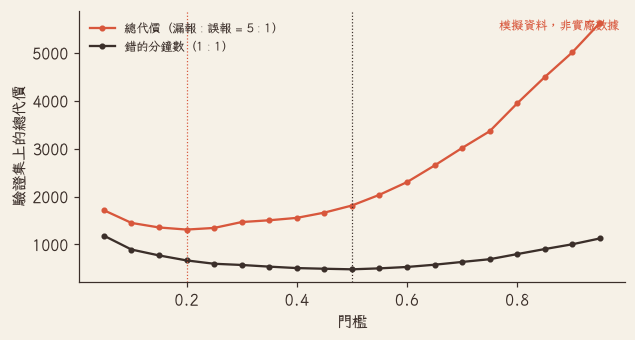

In [8]:
COST_FN, COST_FP = 5.0, 1.0
def total_cost(r, cfn=COST_FN, cfp=COST_FP): return cfn * r["fn"] + cfp * r["fp"]
for r in sweep:
    r["cost_5to1"] = total_cost(r); r["cost_1to1"] = total_cost(r, 1.0, 1.0)
chosen = min(sweep, key=lambda r: r["cost_5to1"])
T_STAR = chosen["thr"]
eq = min(sweep, key=lambda r: r["cost_1to1"])
best_acc = max(sweep, key=lambda r: r["accuracy"])
assert eq["thr"] == best_acc["thr"], "1:1 的總代價最小點應該就是準確率最高點"
print(f"漏報 : 誤報 = 5 : 1 → 總代價最小的門檻 {T_STAR:.2f}")
print(f"漏報 : 誤報 = 1 : 1 → 總代價最小的門檻 {eq['thr']:.2f}（也就是準確率最高的門檻，準確率 {best_acc['accuracy']:.3f}）")
ratio_table = []
for ratio in [1, 3, 5, 10]:
    rr = min(sweep, key=lambda r: total_cost(r, ratio, 1.0))
    ratio_table.append({"ratio": ratio, "thr": rr["thr"]})
print("代價比例和門檻：", "、".join(f"{x['ratio']}:1 → {x['thr']:.2f}" for x in ratio_table))
print("（理論上，如果機率估得很準，最好的門檻是 誤報代價 ÷（誤報代價 + 漏報代價）：1:1 → 0.5，5:1 → 0.17）")

cm_va_star = confusion(y_va, p_va >= T_STAR)
sc_va_star = show(f"\n驗證集，選出的門檻 {T_STAR:.2f}", cm_va_star)
print(f"\n和門檻 0.5 比：漏報 {cm_va_05['fn']:,} → {cm_va_star['fn']:,} 分鐘；誤報 {cm_va_05['fp']:,} → {cm_va_star['fp']:,} 分鐘；"
      f"準確率 {sc_va_05['accuracy']:.3f} → {sc_va_star['accuracy']:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(THR_GRID, [r["cost_5to1"] for r in sweep], "o-", color=RED, ms=3, label="總代價（漏報 : 誤報 = 5 : 1）")
ax.plot(THR_GRID, [r["cost_1to1"] for r in sweep], "o-", color=INK, ms=3, label="錯的分鐘數（1 : 1）")
ax.axvline(T_STAR, color=RED, lw=0.8, ls=":"); ax.axvline(eq["thr"], color=INK, lw=0.8, ls=":")
ax.set_xlabel("門檻"); ax.set_ylabel("驗證集上的總代價"); ax.legend(frameon=False, fontsize=8); tag(ax); plt.show()

## 7. 鎖定之前：檢查各段資料「超過警戒值」的比例
EP05 的教訓：超過警戒值的比例會跟著操作員慢慢調整的進料設定飄動，某一段時間可能一次都沒有。
精確率尤其受這個比例影響（超過的情況越少，誤報占警報的比例就越高），所以測試集必須夠長。
下面**只看答案（0 或 1）**，不看模型分數：訓練、驗證期每天的比例，以及 EP05 已經用過的模擬段落（種子 2028、2030–2034）。

In [9]:
SEG = np.arange(1440, 5 * 1440 - H)   # 每段：模擬 5 天，丟掉第 1 天，留 4 天
daily = [float(y[d * 1440:(d + 1) * 1440 - (H if d == 13 else 0)].mean()) for d in range(14)]
print("第 1–14 天（種子 2026）每天的超過比例：", " ".join(f"{100 * v:.0f}%" for v in daily))
seen_rates = {}
for sd_ in [2028, 2030, 2031, 2032, 2033, 2034]:
    raw_s, _, co_s = simulate(sd_, 5)
    _, _, ys = make_xy(raw_s, co_s)
    seen_rates[sd_] = float(ys[SEG].mean())
print("EP05 用過的 4 天段落：", "、".join(f"{k}：{100 * v:.1f}%" for k, v in seen_rates.items()))
print(f"6 段裡有 {sum(v < 0.02 for v in seen_rates.values())} 段低於 2%：一段 4 天常常幾乎沒有超過的案例。")

第 1–14 天（種子 2026）每天的超過比例： 20% 0% 19% 35% 4% 0% 0% 0% 0% 0% 4% 68% 9% 0%


EP05 用過的 4 天段落： 2028：0.0%、2030：3.3%、2031：1.6%、2032：26.1%、2033：38.5%、2034：0.0%
6 段裡有 3 段低於 2%：一段 4 天常常幾乎沒有超過的案例。


**決定（在產生測試集之前）**：測試集用 **10 段 × 4 天 = 40 天**，是 EP05 的兩倍。種子從 2035 往上，取前 10 個模擬結果在設定範圍內的（規則和 EP05 一樣，只看感測器範圍，不看答案或分數），超出範圍的跳過並記下來。

## 8. 鎖定設定（之後不再改）
- 模型：EP05 的邏輯斯迴歸，權重、標準化參數不變
- 警戒值：接下來一小時 CO 平均 > 30 ppm（示意）
- 門檻：第 6.2 段的規則（漏報 : 誤報 = 5 : 1，總代價最小）在驗證集上選出的值
- 測試集：10 段 × 4 天，種子 2035 起
- 要報告的（事先寫好）：選出門檻的混淆矩陣、準確率、精確率、召回率、總代價；同一份測試集上門檻 0.5 和「永遠不響」的同樣數字（只差門檻這一個因素）；每一段的超過比例、精確率、召回率

In [10]:
LOCK = {"w": W_EP05.tolist(), "mu": mu.tolist(), "sd": sd.tolist(), "thr_ppm": THR, "threshold": T_STAR,
        "rule": "驗證集上總代價最小（漏報 : 誤報 = 5 : 1，0.05 一格）", "cost_fn": COST_FN, "cost_fp": COST_FP, "test_segments": 10, "test_days_per_segment": 4, "test_seed_from": 2035}
print(json.dumps({k: (np.round(v, 4).tolist() if isinstance(v, list) else v) for k, v in LOCK.items()}, ensure_ascii=False))

{"w": [-6.6207, -1.7533, -2.2322, 1.468, -0.3662], "mu": [13.0984, 38792.4532, 965.5008, 8.0328], "sd": [1.1139, 4259.6242, 19.0719, 0.4745], "thr_ppm": 30.0, "threshold": 0.2, "rule": "驗證集上總代價最小（漏報 : 誤報 = 5 : 1，0.05 一格）", "cost_fn": 5.0, "cost_fp": 1.0, "test_segments": 10, "test_days_per_segment": 4, "test_seed_from": 2035}


## 9. 測試集：全新的 40 天，只評估這一次

In [11]:
TEST_SEEDS, SKIPPED, segs = [], [], []
sd_ = LOCK["test_seed_from"]
while len(TEST_SEEDS) < LOCK["test_segments"]:
    try:
        raw_t, _, co_t = simulate(sd_, 5)
    except AssertionError:
        SKIPPED.append(sd_); sd_ += 1; continue
    Xt, co_next_t, yt_ = make_xy(raw_t, co_t)
    segs.append({"seed": sd_, "y": yt_[SEG], "p": predict(Xt[SEG]), "co_next": co_next_t[SEG]})
    TEST_SEEDS.append(sd_); sd_ += 1
print(f"測試用的種子：{TEST_SEEDS}；超出模擬設定範圍而跳過的：{SKIPPED or '無'}")
yt = np.concatenate([g["y"] for g in segs]); pt = np.concatenate([g["p"] for g in segs])
print(f"測試集 {len(yt):,} 分鐘，真的超過警戒值的有 {yt.sum():,} 分鐘（{100 * yt.mean():.1f}%）\n")

cm_te_star = confusion(yt, pt >= T_STAR); sc_te_star = show(f"測試集，鎖定的門檻 {T_STAR:.2f}", cm_te_star)
cm_te_05 = confusion(yt, pt >= 0.5); sc_te_05 = show("測試集，門檻 0.5（對照）", cm_te_05)
cm_te_never = confusion(yt, np.zeros(len(yt), bool)); sc_te_never = show("測試集，永遠不響（對照）", cm_te_never)
cost_te = {k: COST_FN * c["fn"] + COST_FP * c["fp"] for k, c in [("star", cm_te_star), ("t05", cm_te_05), ("never", cm_te_never)]}
print(f"\n測試集總代價（5:1）：門檻 {T_STAR:.2f} → {cost_te['star']:,.0f}；門檻 0.5 → {cost_te['t05']:,.0f}；永遠不響 → {cost_te['never']:,.0f}")

seg_rows = []
print("\n 種子   超過比例   精確率   召回率（鎖定門檻）")
for g in segs:
    c = confusion(g["y"], g["p"] >= T_STAR); s = scores(c)
    seg_rows.append({"seed": g["seed"], "pos_rate": float(g["y"].mean()), **c, "precision": s["precision"], "recall": s["recall"]})
    f = lambda v: "   —  " if v is None else f"{v:.3f}"
    print(f" {g['seed']}   {100 * g['y'].mean():5.1f}%    {f(s['precision'])}    {f(s['recall'])}")

測試用的種子：[2035, 2036, 2037, 2038, 2039, 2040, 2041, 2043, 2044, 2045]；超出模擬設定範圍而跳過的：[2042]
測試集 57,000 分鐘，真的超過警戒值的有 7,262 分鐘（12.7%）

測試集，鎖定的門檻 0.20
  命中  4,922   漏報  2,340
  誤報  5,144   正確不報 44,594
  準確率 0.869  精確率 0.489  召回率 0.678  響警報的時間 17.7%
測試集，門檻 0.5（對照）
  命中  3,201   漏報  4,061
  誤報  1,590   正確不報 48,148
  準確率 0.901  精確率 0.668  召回率 0.441  響警報的時間 8.4%
測試集，永遠不響（對照）
  命中      0   漏報  7,262
  誤報      0   正確不報 49,738
  準確率 0.873  精確率 —（沒有定義）  召回率 0.000  響警報的時間 0.0%

測試集總代價（5:1）：門檻 0.20 → 16,844；門檻 0.5 → 21,895；永遠不響 → 36,310

 種子   超過比例   精確率   召回率（鎖定門檻）
 2035    33.9%    0.707    0.694
 2036     7.7%    0.685    0.812
 2037     1.8%    0.009    0.010
 2038     5.4%    0.340    0.295
 2039     8.9%    0.594    0.602
 2040    14.8%    0.400    0.447
 2041     1.6%       —      0.000
 2043    19.9%    0.446    0.817
 2044    22.0%    0.389    0.794
 2045    11.4%    0.447    0.816


## 10. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖。地震速報（國家級警報）的事件和規則直接引自官方網站和新聞，不是這本 notebook 算的。

In [12]:
def r6(v): return None if v is None else round(float(v), 6)
def rs(s): return {k: (r6(v) if isinstance(v, float) else v) for k, v in s.items()}

vsel = np.arange(0, 2 * 1440, 5)                 # 驗證集前 2 天，每 5 分鐘一點（和 EP05 的 val_series 同一段）
out = {
    "meta": {"model": "EP05 邏輯斯迴歸（權重不變）", "thr_ppm": THR, "horizon_min": H, "unit": "分鐘",
             "val_days": 4, "n_val": int(len(VA)), "test_seeds": TEST_SEEDS, "test_seeds_skipped": SKIPPED, "test_days": 4 * len(TEST_SEEDS),
             "n_test": int(len(yt)), "simulated": True, "label": LABEL},
    "lock": {k: ([round(float(x), 6) for x in v] if isinstance(v, list) else v) for k, v in LOCK.items()},
    "rates": {"train": r6(y[TR].mean()), "val": r6(y_va.mean()), "test": r6(yt.mean()),
              "val_daily": [r6(v) for v in daily[10:]], "seen_segments": {str(k): r6(v) for k, v in seen_rates.items()}},
    "val": {"cm_05": cm_va_05, "sc_05": rs(sc_va_05), "cm_never": cm_va_never, "sc_never": rs(sc_va_never),
            "cm_always": cm_va_always, "sc_always": rs(sc_va_always), "cm_star": cm_va_star, "sc_star": rs(sc_va_star),
            "sweep": [rs(r) for r in sweep], "best_recall": r6(best_recall), "thr_1to1": eq["thr"], "ratio_table": ratio_table},
    "val_series": {"t_h": [round(float(v), 3) for v in vsel / 60], "co_next": [round(float(v), 1) for v in co_next[VA][vsel]],
                   "y": [int(v) for v in y_va[vsel]], "p": [round(float(v), 4) for v in p_va[vsel]]},
    "test": {"cm_star": cm_te_star, "sc_star": rs(sc_te_star), "cm_05": cm_te_05, "sc_05": rs(sc_te_05),
             "cm_never": cm_te_never, "sc_never": rs(sc_te_never), "cost": {k: r6(v) for k, v in cost_te.items()}, "segments": [rs(r) for r in seg_rows]},
}
Path("data").mkdir(exist_ok=True)
Path("data/v07.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print(f"已匯出 data/v07.json（{Path('data/v07.json').stat().st_size / 1024:.0f} KB）")

已匯出 data/v07.json（21 KB）
